In [ ]:
from google.colab import files
import zipfile
# Step 1: Upload zip file
uploaded = files.upload()

Saving dogcatds.zip to dogcatds.zip


In [ ]:
# Step 2: Unzip it
import os
import zipfile

zip_path = "dogcatds.zip"
# Unzip to current directory (root) directly so that 'dogcatds/train' and 'dogcatds/validation' are created
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

# Confirm that directories exist
print("Extracted contents structure:")
for root, dirs, files in os.walk('dogcatds'):
    # limit depth print
    depth = root.count(os.sep)
    if depth < 2:
        print(f"{root}/ - {len(dirs)} directories, {len(files)} files")

Extracted contents structure:
dogcatds/ - 1 directories, 0 files
dogcatds/training_set/ - 2 directories, 0 files


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt


In [ ]:
# Paths - change if needed
TRAIN_DIR = "dataset/train"
VAL_DIR   = "dataset/validation"
IMG_SIZE  = (150, 150)   # common size for small CNNs
BATCH_SIZE = 32
SEED = 15

In [ ]:
#Data augmentation for training with 20% split for validation
train_datagen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=25,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest",
    validation_split=0.2
)

In [ ]:
# Validation data generator using the same split
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [ ]:
TRAIN_DIR = "dogcatds/training_set"

# Training generator
train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training'
)

# Validation generator using the training folder with validation subset split
val_gen = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation'
)

Found 1619 images belonging to 2 classes.
Found 404 images belonging to 2 classes.


In [ ]:
# Load VGG16 without top layers, pretrained on ImageNet

base_model = VGG16(weights='imagenet', include_top=False,
                   input_shape=(150,150,3))

# Freeze base layers so pretrained weights are not updated

base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
#Build Classifier on top
model = Sequential([
base_model,
Flatten(),
Dense(256, activation='relu'),
Dense(1, activation='sigmoid')
])


In [ ]:
#Compile model
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [ ]:
# Define training parameters
EPOCHS = 10

# Train the Model
history = model.fit(
                    train_gen,
                    validation_data=val_gen,
                    epochs=EPOCHS,
                    steps_per_epoch=train_gen.samples // BATCH_SIZE,
                    validation_steps=val_gen.samples // BATCH_SIZE )

Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 23s 356ms/step - accuracy: 0.7253 - loss: 0.5275 - val_accuracy: 0.7943 - val_loss: 0.4546
Epoch 2/10
 1/50 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.8125 - loss: 0.3862

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.8125 - loss: 0.3862 - val_accuracy: 0.8047 - val_loss: 0.4271
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 297ms/step - accuracy: 0.8343 - loss: 0.3710 - val_accuracy: 0.8307 - val_loss: 0.4031
Epoch 4/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7812 - loss: 0.3551 - val_accuracy: 0.8438 - val_loss: 0.3971
Epoch 5/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 281ms/step - accuracy: 0.8563 - loss: 0.3246 - val_accuracy: 0.8385 - val_loss: 0.3853
Epoch 6/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8750 - loss: 0.3498 - val_accuracy: 0.8411 - val_loss: 0.3710
Epoch 7/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 278ms/step - accuracy: 0.8828 - loss: 0.2971 - val_accuracy: 0.8333 - val_loss: 0.3810
Epoch 8/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.8750 - loss: 0.3279 - val_accuracy: 0.8359 - val_loss: 0.3499
Epoch 9/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 274ms/step - accuracy: 0.8822 - loss: 0.2845 - val_accuracy: 0.8516 - val_

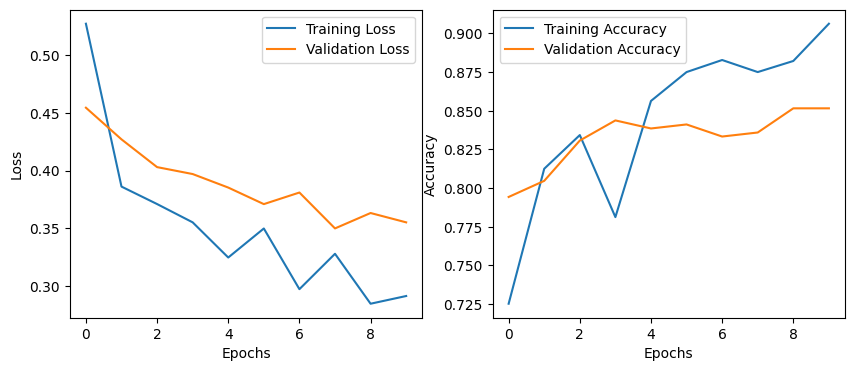

In [ ]:
#Plot Training curves

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
import random

# 1. Class labels
class_names = ["Cat", "Dog"]

# 2. Extract a batch of images and labels from the validation generator
X_test, y_test = next(val_gen)

# 3. Pick 10 random indices from this batch
indices = random.sample(range(len(X_test)), min(20, len(X_test)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


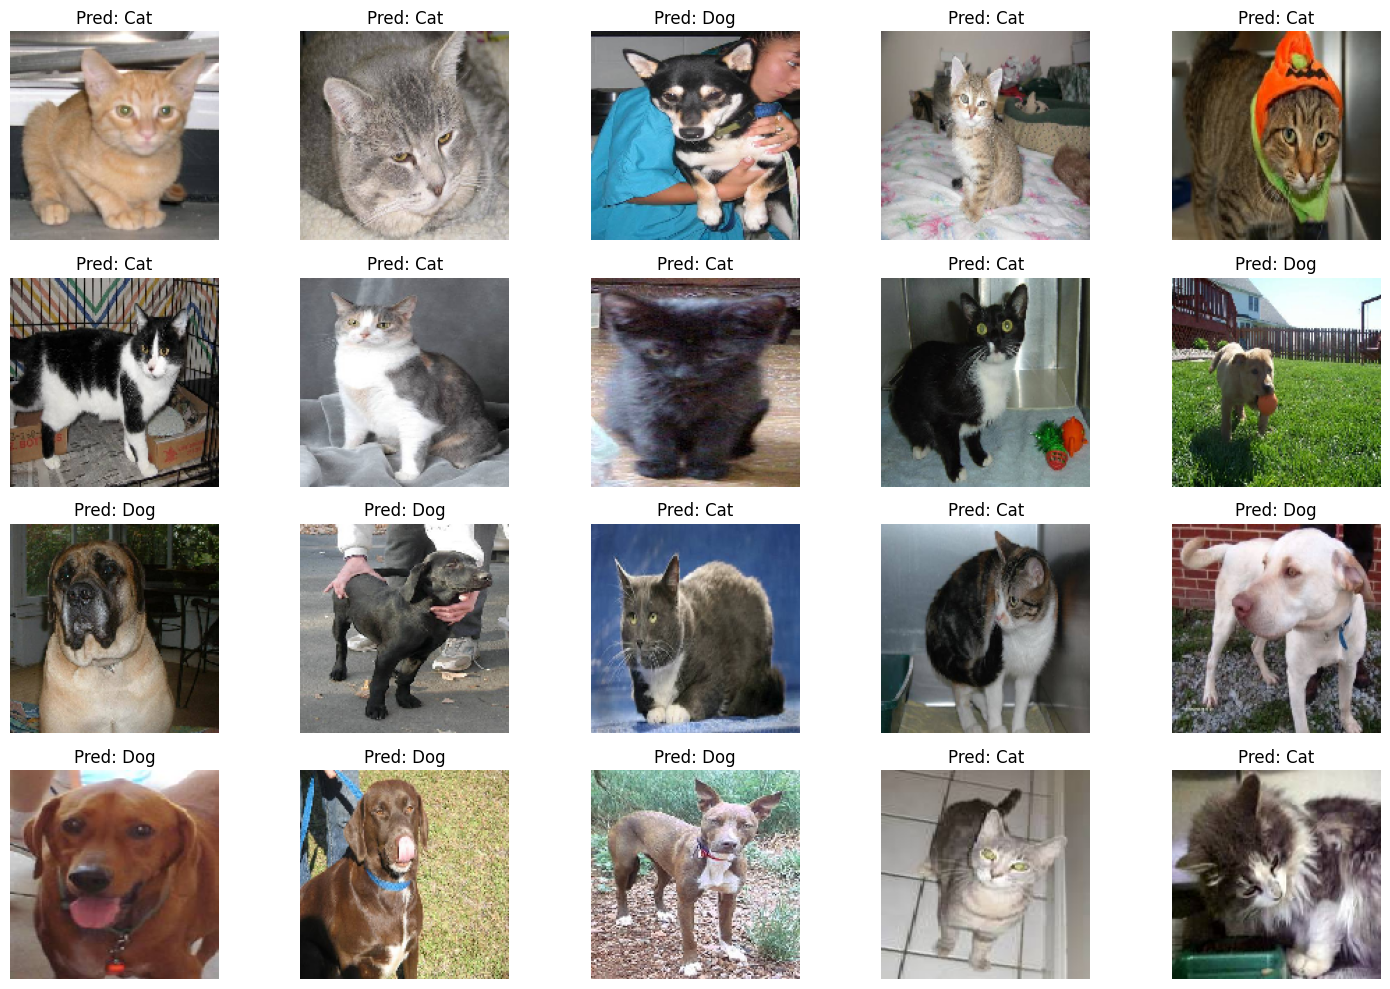

In [ ]:
plt.figure(figsize=(15, 10))

for i, idx in enumerate(indices):
    img = X_test[idx]
    true_label = y_test[idx]

    # Model expects batch, so add extra dimension
    pred_prob = model.predict(img.reshape(1, 150, 150, 3))[0][0]
    pred_label = 1 if pred_prob > 0.5 else 0

    # Show image using a 4x5 grid to fit 20 images
    plt.subplot(4, 5, i + 1)
    plt.imshow(img)
    plt.axis('off')
    plt.title(f"Pred: {class_names[pred_label]}")

plt.tight_layout()
plt.show()